In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


In [4]:

df = pd.read_csv('ecommerce_rfm_segmentation.csv')



In [5]:
df

,CustomerID,Gender,Age,Country,RegistrationDate,LastPurchaseDate,TotalPurchases,TotalSpent,AvgOrderValue,PreferredCategory,DeviceType,LoyaltyTier,IsPremiumMember,ReturnRate,CustomerSupportTickets
0,CUST_1629,Female,62.0,USA,2023-06-18,2025-10-27,84,4463.83,53.14,Sports & Outdoors,Tablet,Gold,True,0.32,3.0
1,CUST_1323,Prefer not to say,55.0,USA,2022-04-05,2025-02-28,3,7597.92,2532.64,Sports & Outdoors,Mobile Web,Platinum,False,0.32,8.0
2,CUST_1011,Female,NaN,UK,2023-01-16,2025-04-13,35,29.28,0.84,Electronics,Desktop,Platinum,False,0.32,6.0
3,CUST_1422,Non-Binary,18.0,India,2023-05-29,2025-04-18,101,4299.07,42.57,Electronics,Mobile App,Basic,True,0.32,8.0
4,CUST_1515,Female,55.0,UK,2023-06-20,2025-04-21,12,6242.72,520.23,Beauty,Mobile Web,Gold,True,0.32,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2620,CUST_1120,Non-Binary,NaN,France,2022-06-07,2025-03-04,98,3274.56,33.41,Beauty,Desktop,Platinum,False,0.32,0.0
2621,CUST_0363,Prefer not to say,53.0,UK,2024-08-27,2025-06-07,4,8207.86,2051.96,Beauty,Desktop,Platinum,True,0.32,0.0
2622,CUST_0194,Female,70.0,UK,2022-09-25,2025-06-04,7,3580.55,511.51,Beauty,Tablet,Gold,False,0.32,NaN
2623,CUST_1615,Male,27.0,Australia,2024-08-24,2025-08-23,98,8389.32,85.61,Beauty,Mobile Web,Gold,False,0.32,0.0


In [6]:
df = df.drop_duplicates()
df = df.dropna()

print("Cleaned Dataset Shape:", df.shape)
df.head()

Cleaned Dataset Shape: (1949, 15)


,CustomerID,Gender,Age,Country,RegistrationDate,LastPurchaseDate,TotalPurchases,TotalSpent,AvgOrderValue,PreferredCategory,DeviceType,LoyaltyTier,IsPremiumMember,ReturnRate,CustomerSupportTickets
0,CUST_1629,Female,62.0,USA,2023-06-18,2025-10-27,84,4463.83,53.14,Sports & Outdoors,Tablet,Gold,True,0.32,3.0
1,CUST_1323,Prefer not to say,55.0,USA,2022-04-05,2025-02-28,3,7597.92,2532.64,Sports & Outdoors,Mobile Web,Platinum,False,0.32,8.0
3,CUST_1422,Non-Binary,18.0,India,2023-05-29,2025-04-18,101,4299.07,42.57,Electronics,Mobile App,Basic,True,0.32,8.0
4,CUST_1515,Female,55.0,UK,2023-06-20,2025-04-21,12,6242.72,520.23,Beauty,Mobile Web,Gold,True,0.32,9.0
5,CUST_0775,Female,43.0,India,2023-04-13,2025-09-17,66,5677.59,86.02,Beauty,Mobile App,Platinum,False,0.32,7.0


In [7]:

df['LastPurchaseDate'] = pd.to_datetime(df['LastPurchaseDate'])

current_date = df['LastPurchaseDate'].max() + pd.Timedelta(days=1)
df['Recency'] = (current_date - df['LastPurchaseDate']).dt.days

rfm = df[['CustomerID', 'Recency', 'TotalPurchases', 'TotalSpent']].copy()
rfm.rename(columns={'TotalPurchases': 'Frequency', 'TotalSpent': 'Monetary'}, inplace=True)

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,CUST_1629,2,84,4463.83
1,CUST_1323,243,3,7597.92
3,CUST_1422,194,101,4299.07
4,CUST_1515,191,12,6242.72
5,CUST_0775,42,66,5677.59


In [9]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])

rfm_scaled_df.head()

,Recency,Frequency,Monetary
0,-1.695862,0.164184,-0.147373
1,1.057482,-1.722106,0.939653
2,0.497673,0.560072,-0.204519
3,0.463399,-1.512519,0.469616
4,-1.238876,-0.254992,0.273607


In [10]:

kmeans = KMeans(n_clusters=4, random_state=42)
rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means Cluster Counts:")
print(rfm['KMeans_Cluster'].value_counts())

K-Means Cluster Counts:
KMeans_Cluster
3    506
1    491
0    477
2    475
Name: count, dtype: int64


In [11]:

dbscan = DBSCAN(eps=0.5, min_samples=5)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

print("DBSCAN Cluster Counts (-1 represents noise/outliers):")
print(rfm['DBSCAN_Cluster'].value_counts())

DBSCAN Cluster Counts (-1 represents noise/outliers):
DBSCAN_Cluster
0    1949
Name: count, dtype: int64


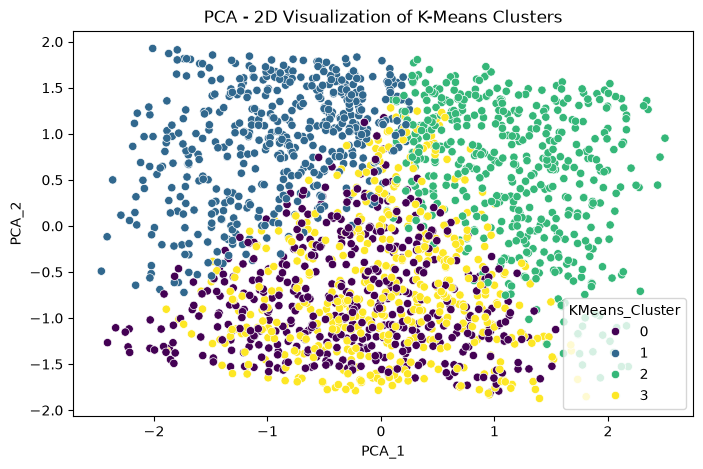

In [12]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(rfm_scaled)

rfm['PCA_1'] = pca_result[:, 0]
rfm['PCA_2'] = pca_result[:, 1]

plt.figure(figsize=(8,5))
sns.scatterplot(x='PCA_1', y='PCA_2', hue='KMeans_Cluster', data=rfm, palette='viridis')
plt.title('PCA - 2D Visualization of K-Means Clusters')
plt.show()

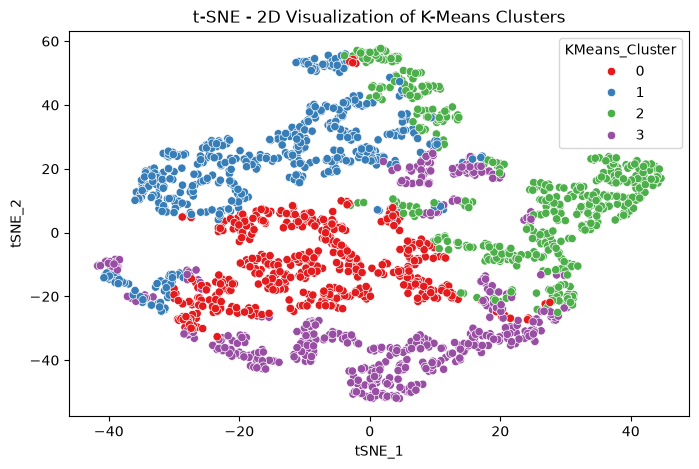

In [13]:
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(rfm_scaled)

rfm['tSNE_1'] = tsne_result[:, 0]
rfm['tSNE_2'] = tsne_result[:, 1]

plt.figure(figsize=(8,5))
sns.scatterplot(x='tSNE_1', y='tSNE_2', hue='KMeans_Cluster', data=rfm, palette='Set1')
plt.title('t-SNE - 2D Visualization of K-Means Clusters')
plt.show()

In [15]:
cluster_means = rfm.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
print("Average metrics per cluster:")
print(cluster_means)

Average metrics per cluster:
                Recency  Frequency  Monetary
KMeans_Cluster                              
0                 75.15      43.80   6449.47
1                221.10      46.11   2895.53
2                207.71     104.70   7548.52
3                 99.08     112.07   2854.73
